In [172]:
from argparse import ArgumentParser, Namespace
import Spectral_Preprocessing as sp
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import json

In [173]:
parser = ArgumentParser()
parser.add_argument("--range-ir-1", dest= "wn_range_ir_1", default = (948,1860))
parser.add_argument("--range-ir-2", dest= "wn_range_ir_2", default = (2698,3002))

parser.add_argument("--range-min-ir", dest= "range_min_ir", type = int, default = 400)
parser.add_argument("--range-max-ir", dest= "range_max_ir", type = int, default = 4000)
parser.add_argument("--interpolate-interval-ir", dest = "interpolate_interval_ir", type = int, default = 1) 

parser.add_argument("--finger-print-exl", dest= "finger_print_exl", type = bool, default = False)
parser.add_argument("--trans-chip", dest= "trans_chip", type = bool, default = False)

parser.add_argument("--background-rule-ir", dest= "background_rule", type = str, default = 'mean')
parser.add_argument("--threshold-mean-intensity-ir", dest= "ths_mean_int_ir", type = float, default = 0)
parser.add_argument("--threshold-total-variation-intensity-ir", dest= "ths_tot_var_int_ir", type = float, default = 0)

parser.add_argument("--range-min-raman", dest= "range_min_raman", type = float, default = 400)
parser.add_argument("--range-max-raman", dest= "range_max_raman", type = float, default = 4000)
parser.add_argument("--interpolate-interval-raman", dest = "interpolate_interval_raman", type = float, default = 1) 

parser.add_argument("--rubberband", dest="rubberband", action="store_true", default=False,)
parser.add_argument("--minmax", dest="minmax", action="store_true", default=False,)
parser.add_argument("--no-interpolate", dest = "no_interpolate", action="store_true", default = False)
parser.add_argument("--nitrogen-calibration", dest="nitrogen_calibration", action="store_true", default=True,)
parser.add_argument("--si-peak", dest= "si_peak", type = float, default = 520)

parser.add_argument("--smooth", dest = "smooth", type = int, default = 0)
parser.add_argument("--baseline", dest = "baseline", type = int, default = 5)

###Sample Code #1: Specify IR and Raman interpolation intervals along with min & max values
args: Namespace = parser.parse_args([]) ###Do not alter this section.
###PLEASE TYPE IN YOUR ARGUMENTS HERE
args.wn_range_ir_1 = (980, 1800) #(675.0,1800)
args.wn_range_ir_2 = (2720, 2970) #(1800,4000)
args.range_min_ir = 675.0 #674.9918 ###enter an integer
args.range_max_ir = 4000.0 #3999.809 ###enter an integer [max value is not included]
args.interpolate_interval_ir = 2 #1.929 ###enter an integer
args.finger_print_exl = False
args.trans_chip = True
args.background_rule = 'total_var'
args.ths_mean_int_ir = 0.043
args.ths_tot_var_int_ir = 0.4543#0.59

args.range_min_raman = 355 #.555542 ###enter an integer or float #530
args.range_max_raman = 3500 #3895.935059 ##enter an integer or float [max value is not included] 
args.interpolate_interval_raman = 2.0 #168021680216802 ###enter an integer or float

args.rubberband = 'specy'#'specy' ###True for rubberband, False for iModPoly
args.minmax = 'snv' ###False for SVT normalization, True for minmax
args.no_interpolate = False ###use sample code 2 if using True for this option.
args.nitrogen_calibration = True ##True for calibration, False for no calibration.
args.si_peak = 520 ###enter an integer or float

In [174]:
directory_name = 'MEC_04_056/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.


path = 'MEC_04_056/'
dirs = os.listdir(path)
files_list = [x for x in dirs if x[-4:]=="ptir"]
files_list

['MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417.ptir',
 'MEC_04_056_BulkLDPE_HDPE_20250418.ptir',
 'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250418.ptir',
 'MEC_04_056_CalciumStearate_AbbyLibrary_20250417.ptir']

In [175]:
args.si_peak = [520]*len(files_list)
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.ptir_to_interpolated_processed_csv(args, 
                                                                                                                                                directory_name,
                                                            ir_export_filename, raman_export_filename, 
                                                            file_list = files_list, transpose = True)

In [176]:
ids_file_name = np.array([x[:-5] for x in ids])
ids_file_name = ids_file_name.astype('<U60')


i = 1
for j, x in enumerate(ids_file_name):
    #idx_.append(i)
    ids_file_name[j] = x +'_'+ str(i)
    if j < ids_file_name.shape[0]-1 and x != ids_file_name[j+1]:
        i = 1
    else:
        i = i + 1
ids_file_name

array(['MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_1',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_2',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_3',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_4',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_5',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_6',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_7',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_8',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_9',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_10',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_11',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_12',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_13',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_14',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary_20250417_15',
       'MEC_04_056_200-9900um_LDPE_RebeccaLibrary

In [177]:
#saturated_wn_dict = {id_:str(list(x))[1:-1] for x, id_ in zip(saturated_wn_list,ids_file_name) if x.shape[0]>0}
#saturated_wn_dict
#with open('gloves_contamination/gloves_data_raman_saturation.json', 'w') as f:
#    json.dump(saturated_wn_dict, f)
    
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['id'] = ids_file_name
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir.to_csv('gloves_contamination/MEC_04_056_ir_norm.csv')

preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['id'] = ids_file_name
preposs_data_raman.to_csv('gloves_contamination/MEC_04_056_raman_norm.csv')

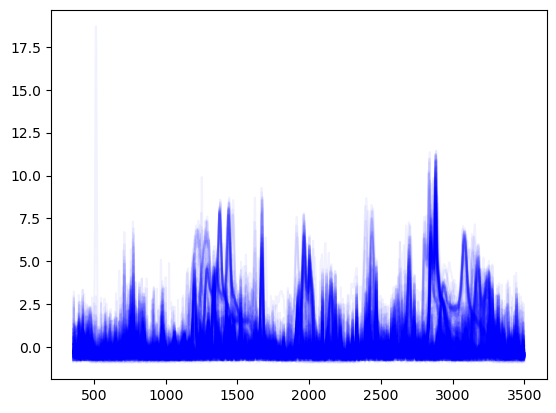

In [185]:
_ = plt.plot(preposs_data_raman.iloc[:,:-3].T, c='b', alpha=.05)

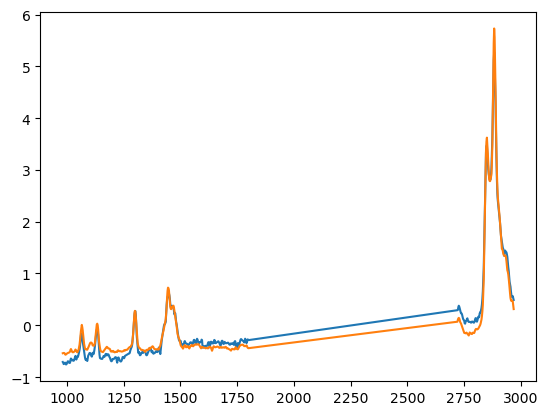

In [178]:
_ = plt.plot(preposs_data_ir.iloc[[-4,-3], :-4].T)

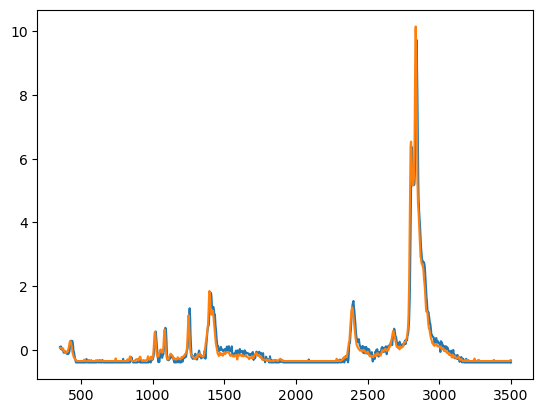

In [179]:
_ = plt.plot(preposs_data_raman.iloc[[-4,-3], :-3].T)

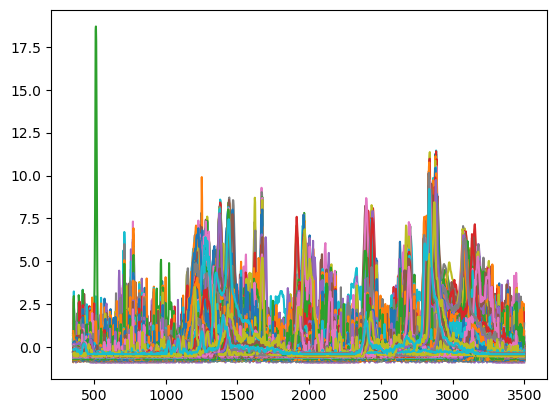

In [180]:
_ = plt.plot(preposs_data_raman.iloc[:,:-3].T)

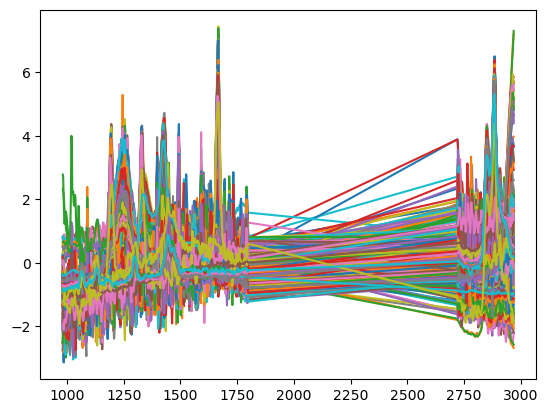

In [181]:
_ = plt.plot(preposs_data_ir.iloc[:,:-4].T)

In [ ]:
#'MEC_04_056/'+files_list


In [190]:
import Orange ###pip install orange3; pip install Orange3-Associate
from Orange.data.io import FileFormat
from orangecontrib.spectroscopy import data ###pip install Orange-Spectroscopy
from orangecontrib.spectroscopy.data import getx


In [168]:
filename = 'MEC_04_056/'+files_list[3]
spectral_type = "IR"
absolute_filename = FileFormat.locate(filename)
reader = FileFormat.get_reader(absolute_filename)


In [171]:
reader.select_sheet(sheet)
reader.sheets

['Raman Intensity']

In [191]:
if spectral_type == "IR":
    sheet = 'OPTIR (mV)'
else:
    sheet = 'Raman Intensity'
reader.select_sheet(sheet)
spectra = sp.read_spectra(reader)
spectra_data = pd.DataFrame(spectra[1])
spectra_data

,0,1,2,3,4,5,6,7,8,9,...,1014,1015,1016,1017,1018,1019,1020,1021,1022,1023
0,1001.333313,1014.059387,1032.967651,1039.738647,1028.680054,1009.717468,1010.160767,1013.920227,1028.572266,1049.519409,...,819.509216,837.844299,859.895691,830.288940,822.204651,827.564819,834.673645,820.666687,821.632568,839.333313
1,1082.000000,1063.971436,1056.597290,1052.911987,1048.006714,1038.525391,1043.478271,1064.854492,1073.471191,1058.855347,...,842.640076,850.836975,859.644165,844.643250,842.600769,833.278931,844.282898,841.139771,845.611633,850.666687
2,1059.333374,1047.137573,1049.081177,1059.183960,1063.466431,1032.388794,1031.164673,1029.525879,1030.021729,1034.427734,...,844.053162,849.879578,868.877258,830.230225,838.693054,826.366943,834.915527,840.838806,831.931824,852.666687
3,1047.333374,1032.486206,1032.184326,1034.917358,1031.568237,1013.659119,1040.555908,1035.178467,1027.608643,1034.510620,...,826.517395,838.158569,837.811829,817.227173,825.075867,814.979248,828.336853,827.135437,834.000000,834.000000
4,1302.666626,1280.395996,1286.001465,1294.501343,1294.558228,1290.870972,1276.223999,1272.779297,1279.840454,1291.333374,...,820.175842,819.139465,835.736206,821.817139,817.696411,815.224487,824.959534,813.425903,816.008179,827.333313
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
207,3474.000000,3419.914062,3438.832031,3485.687988,3525.498291,3527.868652,3626.608398,3579.746582,3536.260498,3593.751221,...,4805.282227,4883.021973,4875.481445,4743.150879,4822.059082,4777.385742,4787.253418,4747.496582,4778.630371,4708.000000
208,1656.000000,1601.118774,1614.164673,1654.890747,1684.908203,1657.517822,1660.482178,1650.070435,1650.333130,1666.347046,...,1603.931763,1590.656372,1593.897217,1567.781006,1575.624023,1575.578613,1519.473755,1564.900024,1578.739624,1615.000000
209,1176.285767,1152.651611,1160.307251,1172.537964,1176.127075,1173.164185,1150.091064,1152.997681,1166.332275,1172.914307,...,957.727600,945.345337,977.982422,956.776184,935.346680,935.408508,944.657959,940.361328,935.380615,945.200012
210,3468.000000,3505.382812,3517.931396,3489.919922,3463.919434,3577.695068,3602.924805,3555.469482,3535.608398,3595.751221,...,2876.416504,2852.229004,2860.368164,2759.582031,2756.739746,2817.778809,2849.050537,2841.200195,2878.536133,2902.000000


In [158]:
spectra_data, coords, label_list = ptir_studio_to_csv('MEC_04_056/'+files_list[0], 
                   spectral_type="IR")


In [193]:
def ptir_studio_to_csv(filename, spectral_type):
    absolute_filename = FileFormat.locate(filename)
    reader = FileFormat.get_reader(absolute_filename)
    if spectral_type == "IR":
        sheet = 'OPTIR (mV)'
    else:
        sheet = 'Raman Intensity'
    reader.select_sheet(sheet)
    spectra = read_spectra(reader)
    spectra_data = pd.DataFrame(spectra[1])
    coords = spectra[2].to_pandas_dfs()[2].reset_index(drop=True)
    spectra_data = spectra_data.reset_index(drop=True)
    spectra_data.columns = spectra[0]
    ###Will work on a better solution later, but this should work for now
    label= ["0" if "PSL" in filename else "1" if "PE" in filename else "2" if "PP" in filename
                    else "3" if "NH3SO5" in filename else "4" if "NaNO3" in filename else "5" if "sucrose" in filename
                    else "6"]
    label_list = label * spectra_data.shape[0]
    return spectra_data, coords, label_list